# Day 9 - Walk-Forward Split Execution Notebook

## Objective

Execute a chronological walk-forward partition (70% train, 15% validation, 15% test) guaranteeing zero lookahead leakage across partitions.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_9_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Timestamped Water Quality Dataset Ingestion

Load timestamped water quality dataset and sort chronologically by timestamp.

In [2]:
df_ts = pd.read_csv("data/processed/water_quality_timestamped.csv")
df_ts["timestamp"] = pd.to_datetime(df_ts["timestamp"])
df_ts = df_ts.sort_values("timestamp").reset_index(drop=True)
print(f"Timestamped Dataset Ingested: {len(df_ts)} records.")
print(f"Temporal Span: {df_ts['timestamp'].min()} to {df_ts['timestamp'].max()}")

Timestamped Dataset Ingested: 3276 records.
Temporal Span: 2025-01-01 00:00:00 to 2025-05-17 11:00:00


## 2. Chronological Cut-Point Determination

Calculate index cut-points at exact 70% and 85% chronological marks.

In [3]:
n = len(df_ts)
cut1 = int(n * 0.70)
cut2 = int(n * 0.85)
train_df = df_ts.iloc[:cut1].copy()
val_df = df_ts.iloc[cut1:cut2].copy()
test_df = df_ts.iloc[cut2:].copy()
print(f"Train Partition:      {len(train_df)} samples ({train_df['timestamp'].min()} -> {train_df['timestamp'].max()})")
print(f"Validation Partition: {len(val_df)} samples ({val_df['timestamp'].min()} -> {val_df['timestamp'].max()})")
print(f"Test Lockbox:         {len(test_df)} samples ({test_df['timestamp'].min()} -> {test_df['timestamp'].max()})")

Train Partition:      2293 samples (2025-01-01 00:00:00 -> 2025-04-06 12:00:00)
Validation Partition: 491 samples (2025-04-06 13:00:00 -> 2025-04-26 23:00:00)
Test Lockbox:         492 samples (2025-04-27 00:00:00 -> 2025-05-17 11:00:00)


## 3. Temporal Precedence and Lookahead Assertion

Assert that train max timestamp precedes validation min timestamp, and validation precedes test.

In [4]:
assert train_df["timestamp"].max() < val_df["timestamp"].min(), "Temporal leak: Train overlaps Validation!"
assert val_df["timestamp"].max() < test_df["timestamp"].min(), "Temporal leak: Validation overlaps Test!"
print("Zero Lookahead Leakage Attestation: Confirmed strictly chronological.")

Zero Lookahead Leakage Attestation: Confirmed strictly chronological.


## 4. Class Prevalence Preservation Check

Verify that target Potability positive rate remains stable across chronological partitions.

In [5]:
p_train = train_df["Potability"].mean()
p_val = val_df["Potability"].mean()
p_test = test_df["Potability"].mean()
print(f"Potability Rates -> Train: {p_train:.4f}, Val: {p_val:.4f}, Test: {p_test:.4f}")

Potability Rates -> Train: 0.3489, Val: 0.4786, Test: 0.4939


## 5. Partition Feature Mean Stability Analysis

Compute drift in feature means across partitions to detect environmental regime shifts.

In [6]:
drift_ph = abs(train_df["ph"].mean() - val_df["ph"].mean())
print(f"pH Mean Drift (Train vs Val): {drift_ph:.4f}")

pH Mean Drift (Train vs Val): 0.1796


## 6. Walk-Forward Split Timeline Visualization

Render multi-color timeline plotting sample indices and partition intervals.

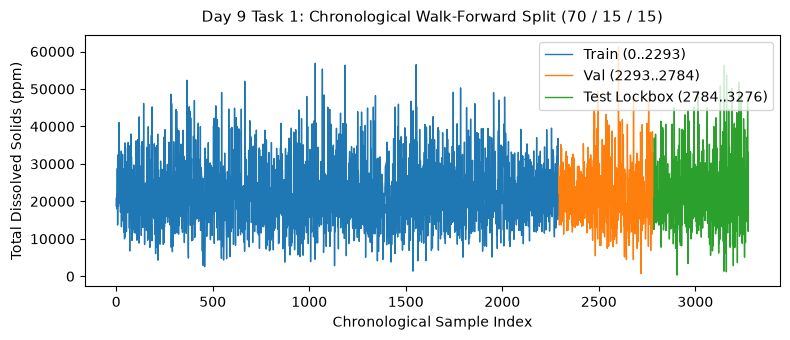

Saved split timeline figure to: Day_Wise_Tasks\Day_9_Task_1\outputs\figures\day9_task1_split_timeline.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(train_df.index, train_df["Solids"], color="#1f77b4", label=f"Train (0..{cut1})", lw=1)
ax.plot(val_df.index, val_df["Solids"], color="#ff7f0e", label=f"Val ({cut1}..{cut2})", lw=1)
ax.plot(test_df.index, test_df["Solids"], color="#2ca02c", label=f"Test Lockbox ({cut2}..{n})", lw=1)
ax.set_title("Day 9 Task 1: Chronological Walk-Forward Split (70 / 15 / 15)", fontsize=11, pad=10)
ax.set_xlabel("Chronological Sample Index")
ax.set_ylabel("Total Dissolved Solids (ppm)")
ax.legend(loc="upper right")
plt.tight_layout()
fig_path = FIG_DIR / "day9_task1_split_timeline.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved split timeline figure to:", fig_path.relative_to(ROOT))

## 7. Walk-Forward Partition Metadata Table Serialization

Serialize partition boundaries and timestamp intervals to CSV.

In [8]:
df_split_meta = pd.DataFrame([
    {"Partition": "Train", "Start_Index": 0, "End_Index": cut1-1, "Count": len(train_df), "Start_Date": str(train_df["timestamp"].min()), "End_Date": str(train_df["timestamp"].max())},
    {"Partition": "Validation", "Start_Index": cut1, "End_Index": cut2-1, "Count": len(val_df), "Start_Date": str(val_df["timestamp"].min()), "End_Date": str(val_df["timestamp"].max())},
    {"Partition": "Test_Lockbox", "Start_Index": cut2, "End_Index": n-1, "Count": len(test_df), "Start_Date": str(test_df["timestamp"].min()), "End_Date": str(test_df["timestamp"].max())}
])
tbl_path = TBL_DIR / "day9_task1_split_metadata.csv"
display(df_split_meta)
df_split_meta.to_csv(tbl_path, index=False)
print("Saved split metadata table to:", tbl_path.relative_to(ROOT))

,Partition,Start_Index,End_Index,Count,Start_Date,End_Date
0,Train,0,2292,2293,2025-01-01 00:00:00,2025-04-06 12:00:00
1,Validation,2293,2783,491,2025-04-06 13:00:00,2025-04-26 23:00:00
2,Test_Lockbox,2784,3275,492,2025-04-27 00:00:00,2025-05-17 11:00:00


Saved split metadata table to: Day_Wise_Tasks\Day_9_Task_1\outputs\tables\day9_task1_split_metadata.csv


## 8. Split Integrity Gate

Assert that partition sample counts exactly match the total dataset.

In [9]:
assert len(train_df) + len(val_df) + len(test_df) == len(df_ts)
print("Day 9 Task 1 Quality Gate: PASSED.")

Day 9 Task 1 Quality Gate: PASSED.


# Day 9 - Assumptions and Methodology

## Assumptions

1. Data must be partitioned along temporal order without random shuffling.
2. Zero lookahead leakage is enforced by strict timestamp boundaries.

## Day 9 Deliverable

Walk-forward split notebook, chronological timeline plot, and partition metadata table.